- Final Project for Code in Place 2026


In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import yfinance as yf

def download_stock_data():

    print("==FINANCIAL DATA COLECTOR ==")
    print("Most popular tickers: \n - RY(RBC)\n - SHOP(Shopify) \n - AAPL(Apple)\n - MSFT(Microsoft)\n - SPY (S&P 500)")

    ticker = input("Which ticker do you want analyse?").strip().upper()

    period = input("Which period do you want analyse?e.g 1y, 2y, 5y")
    if period == "":
        period = "2y"
    print(f"Downloading historical data for {ticker} over {period}...")

    data = yf.download(ticker, period=period)

    if data.empty:
        print(f"❌ Error: Could not find data for ticker '{ticker}'.")
        return None

    filename = f"{ticker}.csv"
    data.to_csv(filename)
    print(f"✅ Success! Data saved to: {filename}")

    return filename


In [18]:
def load_prices(filename):
    """
    Reads a CSV file and extracts the Date and the Closing Price for each day.
    Returns a list of dictionaries, like: [{'date': '2024-09-18', 'price': 284.93}, ...]
    """
    price_history = []
    
    with open(filename, "r") as file:
        lines = file.readlines()
        # We skip the header (first line) and iterate through each data line
        # In files generated by yfinance, the first line is usually the header: Date, Close, ...
        for line in lines[1:]:
            parts = line.strip().split(",")


            # Make sure the line has data and is not empty
            if len(parts) >=2 and parts[1] != "":
                try:
                    date = parts[0]
                    # Convert the closing price from string to float (decimal number)
                    price = float(parts[1])

                    price_history.append({
                        "date": date,
                        "price": price
                    })
                except ValueError:
                    #Skips any secondary header rows if yfinance added them
                    continue
    return price_history

#Test loading the data from your CSV
saved_file = download_stock_data()
history = load_prices(saved_file)

print(f"Loaded {len(history)} trading days.")
print(f"First day: {history[0]['date']} -> ${history[0]['price']:.2f}")
print(f"Last day:  {history[-1]['date']} -> ${history[-1]['price']:.2f}")
    

==FINANCIAL DATA COLECTOR ==
Most popular tickers: 
 - RY(RBC)
 - SHOP(Shopify) 
 - AAPL(Apple)
 - MSFT(Microsoft)
 - SPY (S&P 500)


[*********************100%***********************]  1 of 1 completed

✅ Success! Data saved to: RY.csv
Loaded 501 trading days.
First day: 2024-09-24 -> $117.98
Last day:  2026-09-24 -> $198.79


In [19]:
import math
def calculate_sma(prices,window):
    """Calculates Simple Moving Average for given window."""
    sma = []
    for i in range(len(prices)): 
        if i < window - 1:
            sma.append(None)
        else: 
            subset = prices[i - window + 1 : i + 1]
            sma.append(sum(subset) / window)
    return sma

        

In [20]:
def calculate_support_resistance(prices, window=20):
    """Calculates rolling 20-day high (resistance) and 20-day low (support)"""
    resistances = []
    supports = []
    for i in range(len(prices)):
        if i < window:
            resistances.append(None)
            supports.append(None)
        else:
            subset = prices[i - window : i]
            resistances.append(max(subset))
            supports.append(min(subset))
    return resistances, supports


In [21]:
def calculate_bollinger_bands(prices, window=20, num_std=2):
    """Calculates Bollinger Bands(Middle, Upper, Lower)."""
    sma = calculate_sma(prices, window)
    upper_band = []
    lower_band = []

    for i in range(len(prices)):
        if sma[i] is None: 
            upper_band.append(None)
            lower_band.append(None)
        else:
            subset = prices[i - window + 1 : i + 1]
            mean = sma [i]
            #Standard deviation calc
            variance = sum((x - mean) ** 2 for x in subset) / window
            std_dev = math.sqrt(variance)
            
            upper_band.append(mean + (num_std * std_dev))
            lower_band.append(mean - (num_std * std_dev))

    return sma, upper_band, lower_band

In [23]:
def calculate_rsi(prices, period=14):
    rsi = [None] * len(prices)
    if len(prices) <= period:
        return rsi 

    gains = []
    losses = []

    for i in range(1, len(prices)):
        change = prices[i] - prices[i - 1]
        gains.append(max(change, 0.0))
        losses.append(max(-change, 0.0))

    avg_gain = sum(gains[:period]) / period
    avg_loss = sum(losses[:period]) / period

    if avg_loss == 0: 
        rsi[period] = 100.0
    else: 
        rs = avg_gain / avg_loss
        rsi[period] = 100.0 - (100.0 / (1.0 + rs))
    
    for i in range(period + 1, len(prices)):
        change = prices[i] - prices[i - 1]
        gain = max(change, 0.0)
        loss = max(-change, 0.0)

        avg_gain = ((avg_gain * (period - 1)) + gain) / period
        avg_loss = ((avg_loss * (period - 1)) + loss) / period

        if avg_loss == 0:
            rsi[i] = 100.0
        else:
            rs = avg_gain / avg_loss
            rsi[i] = 100.0 - (100.0 / (1.0 + rs))

    return rsi
print("Mathematical Indicators Engine ready")

Mathematical Indicators Engine ready


In [24]:
def get_user_investment_params():
    """
    Prompts the user for initial starting capital and monthly contribution.
    """
    print("\n===INVESTMENT CAPITAL & CONTRIBUTIONS ===")
    initial_capital = float(input("Enter initial starting capital($): "))
    monthly_contribution = float(input("Enter planned monthly contribution($) [Type 0 if none]:"))

    print(f"💰 Initial Capital: ${initial_capital:,.2f} | Monthly Deposit: ${monthly_contribution:,.2f}\n")
    return initial_capital, monthly_contribution

    

In [25]:
def run_backtest(history, strategy_id, initial_capital, monthly_contribution):
    """
    Simulates the selected trading strategy across the historical data
    using the exact capital and monthly contribution specified by the user.
    """
    prices = [day["price"] for day in history]
    dates = [day["date"] for day in history]

    #Calculate indicators using our engine
    sma20 = calculate_sma(prices, 20)
    sma50 = calculate_sma(prices, 50)
    resistances, supports = calculate_support_resistance(prices, 20)
    _, upper_band, lower_band = calculate_bollinger_bands(prices, 20, 2)
    rsi14 = calculate_rsi(prices, 14)

    cash = initial_capital
    shares = 0
    total_invested = initial_capital
    trades = []
    portfolio_values = []
    entry_price = 0.0

    #Run through historical trading days
    for i in range(len(prices)):
        current_price = prices[i]
        current_date = dates[i]

        #Monthly deposit check (every 21 trading days - 1 calendar month)
        if i > 0 and i % 21 == 0 and monthly_contribution >0:
            cash += monthly_contribution
            total_invested += monthly_contribution
        
        buy_signal = False
        sell_signal = False
        
        #--- 1. ALLOCATION STRATEGIES ----
        if strategy_id == 1: #Buy & Hold
            if i ==0 and cash > 0:
                buy_signal = True
        
        elif strategy_id == 2: #Dollar-Cost Averaging(DCA)
            #Invests available cash monthly as deposits arrive
            if cash > 0 and (i == 0 or 1 % 21 == 0):
                buy_signal = True
                
        elif strategy_id == 3: # Buy the Dip (+5% profit target)
            if i >= 2 and prices[i] < prices[i - 1] < prices[i - 2] and cash > 0 and shares == 0:
                buy_signal = True
            elif shares > 0 and current_price >= entry_price * 1.05:
                sell_signal = True

        elif strategy_id == 4:
            if i == 0 and cash > 0:
                buy_signal = True
            elif shares > 0 and current_price <= entry_price * 0.93:
                sell_signal = True 


        # --- 2. TECHNICAL & CHARTING STRATEGIES --
        elif strategy_id == 5: #Support & Resistance Breakout
            if resistances[i] is not None and supports[i] is not None:
                if current_price > resistances[i] and cash > 0 and shares == 0:
                    buy_signal = True 
                elif current_price < supports[i] and shares > 0:
                    sell_signal = True
                
        elif strategy_id == 6: #Moving Average Crossover(SMA 20 vs SMA50)
            if sma20[i] is not None and sma50[i] is not None and sma20[i - 1] is not None and sma50[i - 1] is not None:
                if sma20[i] > sma50[i] and sma20[i - 1] <= sma50[i - 1] and cash > 0 and shares == 0:
                    buy_signal = True
                elif sma20[i] < sma50[i] and sma20[i - 1] >= sma50[i - 1 ] and shares > 0:
                    sell_signal = True


        elif strategy_id == 7: #Bollinger Bads Reversion
            if lower_band[i] is not None and upper_band[i] is not None:
                if current_price <= lower_band[i] and cash > 0 and shares == 0:
                    buy_signal = True
                elif current_price >=upper_band[i] and shares > 0:
                    sell_signal = True
        
        elif strategy_id == 8: #RSI (30 /70)
            if rsi14[i] is not None:
                if rsi14[i] <30 and cash > 0 and shares == 0:
                    buy_signal = True
                elif rsi14[i] > 70 and shares > 0:
                    sell_signal = True


        #EXECUTE TRADES
        if buy_signal and cash > 0: 
            bought_shares = cash / current_price
            shares += bought_shares
            entry_price = current_price
            trades.append({
                "date": current_date, "type": "BUY", "price": current_price, "shares": bought_shares, "index": i
            })
            cash = 0.0

        elif sell_signal and shares > 0:
            cash += shares * current_price
            trades.append({
                "date": current_date, "type": "SELL", "price": current_price, "shares": shares, "index": i
            })
            shares = 0
            entry_price = 0.0

        # Daily Total Portfolio value
        current_total_value = cash + (shares * current_price)
        portfolio_values.append(current_total_value)


    return {
        "final_value": portfolio_values[-1],
        "total_invested": total_invested,
        "portfolio_values": portfolio_values,
        "trades": trades,
        "prices": prices,
        "dates": dates,
        "indicators": {
            "sma20": sma20,
            "sma50": sma50,
            "resistances": resistances,
            "supports": supports,
            "upper_band": upper_band,
            "lower_band": lower_band,
            "rsi14": rsi14
        }
    }

print("✅ Backtest Simulation Engine ready with custom user capital!")

     


✅ Backtest Simulation Engine ready with custom user capital!


In [26]:
import matplotlib.pyplot as plt
import math

def calculate_performance_metrics(results, risk_free_rate=0.03):
    """
    Computes key financial performance metrics (DAMO611 standards):
    Net Profit, Total Return, Annualized Volatility, Sharpe Ratio, Max Drawdown.
    """
    portfolio_values = results["portfolio_values"]
    total_invested = results["total_invested"]
    final_val = results["final_value"]

    # 1. Net Profit & Total Return
    net_profit = final_val - total_invested
    total_return_pct = (net_profit / total_invested) * 100.0
    
    # 2. Daily Returns calculation
    daily_returns = []
    for i in range(1, len(portfolio_values)):
        prev_val = portfolio_values[i - 1]
        if prev_val > 0:
            ret = (portfolio_values[i] - prev_val) / prev_val
            daily_returns.append(ret)

    # 3. Annualized Return (CAGR) & Volatility
    num_days = len(portfolio_values)
    years = num_days / 252.0 if num_days >= 252 else 1.0
    
    if len(daily_returns) > 1:
        mean_daily_return = sum(daily_returns) / len(daily_returns)
        variance = sum((r - mean_daily_return) ** 2 for r in daily_returns) / (len(daily_returns) - 1)
        daily_volatility = math.sqrt(variance)
        annualized_volatility = daily_volatility * math.sqrt(252)
        annualized_return = (mean_daily_return * 252)
    else:
        annualized_volatility = 0.0
        annualized_return = 0.0

    # 4. Sharpe Ratio (DAMO611 Module 4 formula)
    if annualized_volatility > 0:
        sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility
    else:
        sharpe_ratio = 0.0
    
    # 5. Maximum Drawdown (Peak-to-Trough Decline)
    max_peak = portfolio_values[0]
    max_drawdown = 0.0
    for val in portfolio_values:
        if val > max_peak:
            max_peak = val
        drawdown = (max_peak - val) / max_peak if max_peak > 0 else 0
        if drawdown > max_drawdown:
            max_drawdown = drawdown
            
    return {
        "net_profit": net_profit,
        "total_return_pct": total_return_pct,
        "annualized_volatility": annualized_volatility * 100.0,
        "sharpe_ratio": sharpe_ratio,
        "max_drawdown_pct": max_drawdown * 100.0,
        "total_trades": len(results["trades"])
    }


In [29]:
def plot_simulation_results(results, strategy_name, ticker_name):
    """
    Plots the price history with Support/Resistance, Indicators, and Trade Signals.
    """
    dates = results["dates"]
    prices = results["prices"]
    trades = results["trades"]
    portfolio_values = results["portfolio_values"]
    indicators = results["indicators"]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
    
    # --- Top Subplot: Stock Price & Strategy Overlays ---
    ax1.plot(prices, label=f"{ticker_name} Close Price", color="#1f77b4", linewidth=1.8, zorder=2)
    
    # 1. Overlay Support & Resistance if available
    if "Support" in strategy_name or "Breakout" in strategy_name:
        if indicators["resistances"][20] is not None:
            ax1.plot(indicators["resistances"], label="Resistance (20-day High)", color="#2ca02c", linestyle="--", linewidth=1.5, alpha=0.8)
        if indicators["supports"][20] is not None:
            ax1.plot(indicators["supports"], label="Support (20-day Low)", color="#d62728", linestyle="--", linewidth=1.5, alpha=0.8)
            
    # 2. Overlay Moving Averages if applicable
    elif "SMA" in strategy_name or "Crossover" in strategy_name:
        if indicators["sma20"][20] is not None:
            ax1.plot(indicators["sma20"], label="SMA 20 (Fast)", color="orange", linestyle="--", alpha=0.8)
        if indicators["sma50"][50] is not None:
            ax1.plot(indicators["sma50"], label="SMA 50 (Slow)", color="purple", linestyle="--", alpha=0.8)
            
    # 3. Overlay Bollinger Bands if applicable
    elif "Bollinger" in strategy_name:
        if indicators["upper_band"][20] is not None:
            ax1.plot(indicators["upper_band"], label="Upper Band (+2σ)", color="gray", linestyle=":", alpha=0.7)
            ax1.plot(indicators["lower_band"], label="Lower Band (-2σ)", color="gray", linestyle=":", alpha=0.7)
            ax1.fill_between(range(len(prices)), indicators["lower_band"], indicators["upper_band"], color="gray", alpha=0.1)

    # --- Plot Trade Signal Markers directly on the price line ---
    buy_indices = [t["index"] for t in trades if t["type"] == "BUY"]
    buy_prices = [t["price"] for t in trades if t["type"] == "BUY"]
    sell_indices = [t["index"] for t in trades if t["type"] == "SELL"]
    sell_prices = [t["price"] for t in trades if t["type"] == "SELL"]
    
    if buy_indices:
        ax1.scatter(buy_indices, buy_prices, marker="^", color="#00FF00", edgecolor="black", s=130, label="BUY Signal", zorder=6)
    if sell_indices:
        ax1.scatter(sell_indices, sell_prices, marker="v", color="#FF0000", edgecolor="black", s=130, label="SELL Signal", zorder=6)
        
    ax1.set_title(f"Quantitative Backtest: {strategy_name} on {ticker_name}", fontsize=14, fontweight="bold")
    ax1.set_ylabel("Price ($)", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.4)
    ax1.legend(loc="upper left", framealpha=0.9)
    
    # --- Bottom Subplot: Portfolio Equity Curve ---
    ax2.plot(portfolio_values, label="Portfolio Value ($)", color="#2ca02c", linewidth=2)
    ax2.axhline(results["total_invested"], color="black", linestyle="--", alpha=0.7, label=f"Total Invested (${results['total_invested']:,.2f})")
    ax2.set_ylabel("Portfolio Value ($)", fontsize=11)
    ax2.set_xlabel("Trading Days Elapsed", fontsize=11)
    ax2.grid(True, linestyle="--", alpha=0.4)
    ax2.legend(loc="upper left", framealpha=0.9)
    
    plt.tight_layout()
    plt.show()

print("✅ Enhanced Visual Plotting Engine ready with Support & Resistance lines!")


✅ Enhanced Visual Plotting Engine ready with Support & Resistance lines!


      QUANTITATIVE TRADING & INVESTMENT BACKTESTER 🇨🇦📈          

==FINANCIAL DATA COLECTOR ==
Most popular tickers: 
 - RY(RBC)
 - SHOP(Shopify) 
 - AAPL(Apple)
 - MSFT(Microsoft)
 - SPY (S&P 500)


[*********************100%***********************]  1 of 1 completed

✅ Success! Data saved to: RY.csv

✅ Successfully loaded 501 trading days for RY.

===INVESTMENT CAPITAL & CONTRIBUTIONS ===


💰 Initial Capital: $500.00 | Monthly Deposit: $100.00


🚀 Running backtest for: [Support $ Resistance Breakout (20-day High/Low)]...

    EXECUTIVE PERFORMANCE REPORT: RY     
Strategy:       Support $ Resistance Breakout (20-day High/Low)
Total Invested:         $2,800.00
Final Portfolio Value:  $3,693.21
Net Profit / Loss:     $893.21 (+31.90%)
-----------------------------------------------------------------
--- RISK & PERFORMANCE METRICS (DAMO611 STANDARDS) ---
Annualized Volatility: 32.71%
Sharpe Ratio:          3.15
Max Drawdown:          6.39%
Total Trades Executed: 14
-----------------------------------------------------------------
Passive Benchmark Return (Buy & Hold): +68.68%
⚠️ UNDERPERFORMANCE: -36.78% below the benchmark.



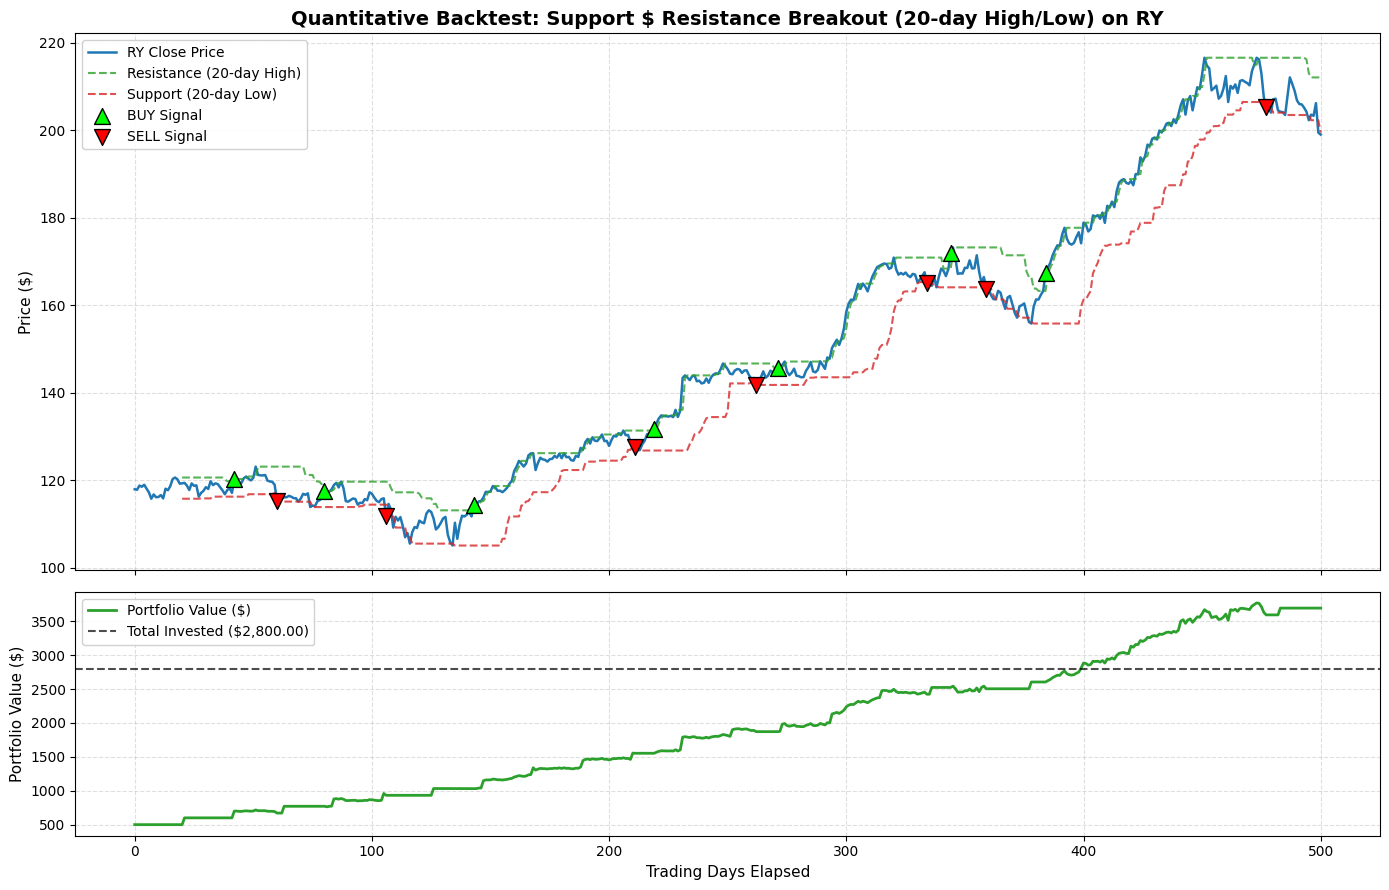

In [30]:
def main():
    print("=================================================================")
    print("      QUANTITATIVE TRADING & INVESTMENT BACKTESTER 🇨🇦📈          ")
    print("=================================================================\n")

    # 1. Download or select stock data
    stock_file = download_stock_data()
    if not stock_file:
        return

    ticker_name = stock_file.replace(".csv", "")
    history = load_prices(stock_file)
    print(f"\n✅ Successfully loaded {len(history)} trading days for {ticker_name}.")
    
    #2. Get user's investment capital parameters
    initial_capital, monthly_contribution = get_user_investment_params()

    # Strategy names dictionary
    strategy_names = {
        1: "Buy & Hold (Passive Benchmark)",
        2: "Dollar-Cost Averaging (Monthly DCA)",
        3: "Buy the Dip (Mean Reversion)",
        4: "Risk-Managed Stop Loss (-7% Stop)",
        5: "Support $ Resistance Breakout (20-day High/Low)",
        6: "Moving Average Crossover (SMA 20 vs SMA 50)",
        7: "Bollinger Bands Reversion (2 Std Dev)",
        8: "RSI Momentum/Oversold (30/70 Levels)"
    }

    #3. Strategy Selection Menu
    menu_prompt = (
        "\nSELECT STRATEGY (Type 1 to 8):\n"
        "[1] Buy & Hold\n"
        "[2] Monthly DCA\n"
        "[3] Buy the Dip\n"
        "[4] Stop Loss (-7%)\n"
        "[5] Support/Resistance Breakout\n"
        "[6] SMA Crossover (20 vs 50)\n"
        "[7] Bollinger Bands\n"
        "[8] RSI (30/70)\n"
        "Enter number (1-8): "
    )

    strategy_id = int(input(menu_prompt).strip())

    if strategy_id not in strategy_names:
        print("❌ Invalid selection. Please choose a number between 1 and 8.")
        return

    chosen_strategy = strategy_names[strategy_id]
    print(f"\n🚀 Running backtest for: [{chosen_strategy}]...")

    # 4. Run Backtest Simulation
    results = run_backtest(history, strategy_id, initial_capital, monthly_contribution)
    metrics = calculate_performance_metrics(results)

    # Also run passive Buy & Hold as a benchmark comparison
    benchmark_results = run_backtest(history, 1, initial_capital, 0.0)
    benchmark_metrics = calculate_performance_metrics(benchmark_results)

    # 5. Display Executive Financial Performance Report
    print("\n" + "=" * 65)
    print(f"    EXECUTIVE PERFORMANCE REPORT: {ticker_name}     ")
    print("=" * 65)
    print(f"Strategy:       {chosen_strategy}")
    print(f"Total Invested:         ${results['total_invested']:,.2f}")
    print(f"Final Portfolio Value:  ${results['final_value']:,.2f}")
    print(f"Net Profit / Loss:     ${metrics['net_profit']:,.2f} ({metrics['total_return_pct']:+.2f}%)")
    print("-" * 65)
    print("--- RISK & PERFORMANCE METRICS (DAMO611 STANDARDS) ---")
    print(f"Annualized Volatility: {metrics['annualized_volatility']:.2f}%")
    print(f"Sharpe Ratio:          {metrics['sharpe_ratio']:.2f}")
    print(f"Max Drawdown:          {metrics['max_drawdown_pct']:.2f}%")
    print(f"Total Trades Executed: {metrics['total_trades']}")
    print("-" * 65)
    print(f"Passive Benchmark Return (Buy & Hold): {benchmark_metrics['total_return_pct']:+.2f}%")


    # Alpha comparison
    alpha = metrics['total_return_pct'] - benchmark_metrics['total_return_pct']
    if alpha > 0:
        print(f"🏆 OUTPERFORMANCE (Alpha): +{alpha:.2f}% above the benchmark!")
    else:
        print(f"⚠️ UNDERPERFORMANCE: {alpha:.2f}% below the benchmark.")
    print("=" * 65 + "\n")

    # 6. Plot the visual interactive chart
    plot_simulation_results(results, chosen_strategy, ticker_name)

# Run the application
if __name__ == "__main__":
    main()




